# When do GNNs help sparse radio-map interpolation? Regime map, strawman defence and the training-scale axis (round 5)

**What this notebook adds to rounds 1-4.** Rounds 1-4 showed that label-aware GCN/GAT lose to IDW/kriging at 5-300 labels per map and that KGNN's edge comes from its fixed local-kriging structure, not from learning. A reviewer will say two things: *"you tested the wrong regime"* and *"your GNN is a strawman"*. This notebook answers both and turns the paper's question into a measurable one.

| Part | Question | Needs torch / GPU? | Needs earlier results? |
|---|---|---|---|
| **A** | Is the learned-vs-classical gain a *function of target properties* (noise share, labels per correlation range, LOS share, side-info informativeness)? Where is the crossover? Does the map predict gains on an unseen dataset (leave-one-family-out)? | no | yes (your `*.jsonl`) |
| **B** | Do the new methods obey the no-test-label-leak rule? | yes | no |
| **C** | Is the GNN a strawman? C1: a GNN with the *same* side information as `rk_side` and a zero-initialised correction head. C2: how much does validation-based checkpoint selection cost at <= 30 labels? C3: does a large tuning budget change anything? | yes | no (fresh wall pool) |
| **D** | **The missing axis.** Pre-train GNNs and a neural process on K = 4 ... 64 source layouts, evaluate on held-out layouts at 100 ... 2000 labels. Is there *any* scale at which a learned model beats classical methods? | yes (GPU helps) | no |
| **E** | Extra baselines (GP with max-likelihood Matern-ARD kernel, thin-plate spline, coordinate MLP) on your existing real Wi-Fi units. | yes (coord MLP) | yes (unit caches) |
| **F** | Templates: more real datasets, DeepMIMO channel-power target. | - | - |
| **G** | One claim table + the wording the data allow. | no | - |

**Honest status.** The pure numpy/sklearn/pandas code (Part A statistics, GP, thin-plate spline, scale tables) was executed on synthetic data while this was written. The **torch code (coordinate MLP, neural process, `rk_gcn`) and every call into your `rmbench_ext*.py` executor were NOT run** (no torch in the authoring sandbox). Run with `SMOKE = True` first; Part B checks plumbing and leak-freedom.

**Pre-registration.** Contrast lists, margin and claim rules are frozen in section 1 before any new number exists; everything here was *designed after seeing rounds 1-4* and the file says so.

## 1. Setup and frozen plan

In [1]:
import os, sys, glob, json, warnings, importlib
sys.path.insert(0, os.getcwd()); warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

SMOKE   = True                                  # True: tiny fake-data pass to check plumbing. Set False for the real run.
N_JOBS  = max(1, (os.cpu_count() or 2) - 1)
ROOT    = "results_ext5_smoke" if SMOKE else "results_ext5"; os.makedirs(ROOT, exist_ok=True); os.makedirs(f"{ROOT}/figures", exist_ok=True)

# --- where rounds 1-4 wrote their results / unit caches (edit if yours differ) -----------------------------------------
RESULT_GLOBS = ["results_conf3/*/*_random.jsonl", "results_conf3/*/*_blocked.jsonl",
                "results_conf2/*/*_random.jsonl", "results_conf2/*/*_blocked.jsonl",
                "results_ext2/*/*_random.jsonl",  "results_ext2/*/*_blocked.jsonl"]
CACHE_DIRS   = sorted(set(glob.glob("results_*/cache_*") + glob.glob("rmbench_cache*")))
DROP_SCENARIOS = ("i1_2p5",)     # 100% LOS, y_std 1.2 dB, RMSE ~0.07 dB: a 5% win is ~0.004 dB. Demoted to descriptive (see plan item 6).

MARGIN_PCT = 2.0                 # equivalence margin, as in rounds 2-4
import rmbench_core as rc
print("cache dirs found:", CACHE_DIRS)

cache dirs found: ['results_conf2/cache_dm_path', 'results_conf2/cache_sod', 'results_conf2/cache_uji', 'results_conf2/cache_wall', 'results_conf3/cache_dm_path', 'results_conf3/cache_sod', 'results_conf3/cache_uji', 'results_conf3/cache_wall', 'results_ext2/cache_dm_path', 'results_ext2/cache_uji', 'results_ext2/cache_wall', 'rmbench_cache', 'rmbench_cache_channel', 'rmbench_cache_dm_nb', 'rmbench_cache_uji']


In [2]:
%%writefile rmbench_ext5.py
"""rmbench_ext5: regime-map statistics, extra baselines, strawman diagnostics and the training-scale experiment.

Sits next to rmbench_core / rmbench_nn / rmbench_ext / rmbench_ext2 (all unchanged). Only ADDS code.
Pure numpy/pandas/sklearn parts (sections 1-3) import without torch; torch parts are guarded by HAVE_TORCH.
Every new predictor has the signature   f(u, tr, te, prep, hp, seed) -> (prediction in dBm at te, info dict)   and only reads
prep['res'][tr] (labels at tr). Test labels enter only through the RMSE (see leak_check).
"""
from __future__ import annotations
import os, re, glob, json, time, math, warnings, traceback
import numpy as np, pandas as pd
import rmbench_core as rc

try:
    import torch, torch.nn as nn, torch.nn.functional as F
    HAVE_TORCH = True
except Exception:                                   # analysis-only environment
    HAVE_TORCH = False

MARGIN_PCT = 2.0            # equivalence margin used in rounds 2-4
_GRAPHS = {}

# =============================================================================== 1. unit covariates (descriptive, never fed to a model)
def _poly2(P):
    x = (P[:, 0] - P[:, 0].mean()) / (P[:, 0].std() + 1e-9); y = (P[:, 1] - P[:, 1].mean()) / (P[:, 1].std() + 1e-9)
    return np.column_stack([np.ones(len(P)), x, y, x * x, x * y, y * y])

def unit_covariates(u, max_pts=400, seed=0, trend="poly2"):
    """Properties of the *target* that decide whether any interpolator can win.
    trend='poly2' (default): residual of a quadratic surface fit, identical definition for every dataset (also unknown-TX Wi-Fi).
    noise_frac = nugget / (nugget + partial sill) of an exponential variogram of that residual (1 = pure noise, 0 = smooth field)."""
    N = len(u["y"]); rng = np.random.default_rng(seed); idx = np.sort(rng.choice(N, min(N, max_pts), replace=False))
    P = np.asarray(u["pos"], float)[idx]; y = np.asarray(u["y"], float)[idx]
    if trend == "logd" and "d" in u and np.ptp(u["d"]) > 1e-6 and int(np.asarray(u.get("tx_known", 1))) == 1:
        d = np.asarray(u["d"], float)[idx]; a, n = rc.fit_trend(d, y); r = y - rc.trend_eval(d, a, n)
    else:
        A = _poly2(P); r = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
    nug, ps, rg = rc.fit_variogram(P, r, "exp")
    full = np.asarray(u["pos"], float); area = float(np.ptp(full[:, 0]) * np.ptp(full[:, 1]) + 1e-9)
    out = dict(noise_frac=float(nug / (nug + ps + 1e-12)), vrange=float(rg), area=area, n_pool=N, resid_std=float(r.std()),
               y_std=float(np.std(u["y"])), los_frac=float(np.mean(u["los"])) if "los" in u else np.nan, side_r2=np.nan)
    if "side" in u:
        S = np.asarray(u["side"], float)[idx]; A = np.column_stack([np.ones(len(S)), S]); b = np.linalg.lstsq(A, r, rcond=None)[0]
        out["side_r2"] = float(1 - ((r - A @ b) ** 2).sum() / (((r - r.mean()) ** 2).sum() + 1e-12))
    return out

def covariate_table(units, cache_dirs, **kw):
    rows = []
    for n in sorted(set(units)):
        u = None
        for cd in cache_dirs:
            if os.path.exists(os.path.join(cd, "units", n.replace("|", "__") + ".npz")):
                u = rc.get_unit(n, cd); break
        if u is None: continue
        try: rows.append(dict(unit=n, **unit_covariates(u, **kw)))
        except Exception as e: rows.append(dict(unit=n, err=repr(e)))
    return pd.DataFrame(rows).set_index("unit") if rows else pd.DataFrame()

def add_density_covariates(g):
    """labels per squared correlation range (the 'how many labels does a correlation cell contain' number) and friends."""
    g = g.copy()
    g["lpr"] = g.density * g.vrange ** 2 / g.area; g["log_lpr"] = np.log10(g.lpr.clip(lower=1e-6))
    g["spacing_ratio"] = np.sqrt(g.area / g.density) / g.vrange; g["log_density"] = np.log10(g.density)
    g["is_blocked"] = (g["split"] == "blocked").astype(float) if "split" in g else 0.0
    return g

# =============================================================================== 2. results loading, paired gains, verdicts
def load_results(patterns):
    frames = []
    for pat in patterns:
        for p in sorted(glob.glob(pat)):
            d = rc.read_results(p)
            if len(d): d["src"] = os.path.basename(p); d["family"] = os.path.basename(os.path.dirname(p)); frames.append(d)
    if not frames: return pd.DataFrame()
    df = pd.concat(frames, ignore_index=True)
    df["split"] = np.where(df.src.str.contains("blocked"), "blocked", "random")
    return df

def unit_rmse(df):
    ok = df[df.status == "ok"]; keys = [c for c in ("family", "split", "scenario", "parent", "unit", "density") if c in ok]
    return ok.groupby(keys + ["name"], as_index=False).rmse.mean()

def paired_gain(df, A, B):
    """One row per (unit, density[, family, split]); gain > 0 means A better. Replicates are averaged first."""
    u = unit_rmse(df); keys = [c for c in u.columns if c not in ("name", "rmse")]
    w = u.pivot_table(index=keys, columns="name", values="rmse", dropna=False)
    if A not in w.columns or B not in w.columns or A == B: return pd.DataFrame()
    w = w[[A, B]].dropna().reset_index(); w["gain_db"] = w[B] - w[A]; w["gain_pct"] = 100 * w.gain_db / w[B]
    w["rmse_A"], w["rmse_B"] = w[A], w[B]; w["A"], w["B"] = A, B
    return w.drop(columns=[A, B])

def _cluster_mean_ci(values, clusters, n_boot=4000, seed=0):
    d = pd.DataFrame(dict(v=np.asarray(values, float), c=np.asarray(clusters))).dropna()
    m = d.groupby("c").v.mean().values
    if len(m) < 2: return np.nan, np.nan, np.nan, len(m)
    bs = np.random.default_rng(seed).choice(m, (n_boot, len(m))).mean(1)
    return float(m.mean()), float(np.quantile(bs, .025)), float(np.quantile(bs, .975)), len(m)

def verdict(lo, hi, margin=MARGIN_PCT):
    if not (np.isfinite(lo) and np.isfinite(hi)): return "too few clusters"
    if lo > -margin and hi < margin: return f"equivalent (CI within +/-{margin:g}%)"
    if lo > 0: return "A better"
    if hi < 0: return "A worse"
    return "inconclusive"

def contrast_table(df, contrasts, by=("family", "split", "scenario", "density"), margin=MARGIN_PCT, min_clusters=4):
    """Per group: cluster (parent) bootstrap CI of the mean relative gain, dB gain, Wilcoxon/sign-flip p (Holm over the whole table)."""
    rows = []
    for A, B in contrasts:
        w = paired_gain(df, A, B)
        if not len(w): continue
        by_ = [c for c in by if c in w]
        for key, g in w.groupby(by_):
            key = key if isinstance(key, tuple) else (key,)
            m, lo, hi, nc = _cluster_mean_ci(g.gain_pct, g.parent)
            pm = g.groupby("parent")[["rmse_A", "rmse_B"]].mean()
            t = rc.paired_test(pm.rmse_B.values, pm.rmse_A.values) if nc >= 2 else dict(p=1.0)
            rows.append(dict(zip(by_, key), A=A, B=B, n_clusters=nc, mean_gain_pct=m, ci_lo=lo, ci_hi=hi, mean_gain_db=float(g.groupby("parent").gain_db.mean().mean()),
                             p=t["p"], verdict=verdict(lo, hi, margin) if nc >= min_clusters else "too few clusters"))
    out = pd.DataFrame(rows)
    if len(out): out["p_holm"] = rc.holm(out.p.values)
    return out

# =============================================================================== 3. regime regression + bins
def cluster_ols(w, y, xs, cluster="parent", n_boot=2000, seed=0, max_nan_frac=0.3):
    """OLS of y on standardised covariates; CIs by bootstrap over clusters (parents). Degenerate / mostly-missing covariates are dropped and listed."""
    keep, dropped = [], []
    for x in xs:
        if x not in w or w[x].isna().mean() > max_nan_frac or w[x].nunique() < 2: dropped.append(x)
        else: keep.append(x)
    d = w[[y, cluster] + keep].replace([np.inf, -np.inf], np.nan).dropna()
    if len(keep) == 0 or len(d) < 12 or d[cluster].nunique() < 5: return pd.DataFrame(), dropped
    mu, sd = d[keep].mean(), d[keep].std().replace(0, 1.0)
    X = np.column_stack([np.ones(len(d)), ((d[keep] - mu) / sd).values]); Y = d[y].values
    beta = np.linalg.lstsq(X, Y, rcond=None)[0]; groups = [np.where(d[cluster].values == c)[0] for c in d[cluster].unique()]
    rng = np.random.default_rng(seed); B = []
    for _ in range(n_boot):
        idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
        B.append(np.linalg.lstsq(X[idx], Y[idx], rcond=None)[0])
    B = np.array(B); r2 = 1 - ((Y - X @ beta) ** 2).sum() / (((Y - Y.mean()) ** 2).sum() + 1e-12)
    out = pd.DataFrame(dict(term=["intercept"] + keep, coef_per_sd=beta, ci_lo=np.quantile(B, .025, 0), ci_hi=np.quantile(B, .975, 0),
                            p_boot=[min(1.0, 2 * min((b > 0).mean(), (b < 0).mean())) for b in B.T]))
    out["n_rows"] = len(d); out["n_clusters"] = len(groups); out["r2_in_sample"] = r2
    return out, dropped

def lofo_r2(w, y, xs, group="family"):
    """Leave-one-family-out R^2 of the regime model (does the map predict gains in a dataset it has never seen?)."""
    d = w[[y, group] + xs].replace([np.inf, -np.inf], np.nan).dropna(); rows = []
    for gname in d[group].unique():
        tr, te = d[d[group] != gname], d[d[group] == gname]
        if len(tr) < 12 or len(te) < 5: continue
        mu, sd = tr[xs].mean(), tr[xs].std().replace(0, 1.0)
        Xa = np.column_stack([np.ones(len(tr)), ((tr[xs] - mu) / sd).values]); b = np.linalg.lstsq(Xa, tr[y].values, rcond=None)[0]
        pred = np.column_stack([np.ones(len(te)), ((te[xs] - mu) / sd).values]) @ b
        sse = ((te[y].values - pred) ** 2).sum(); sst = ((te[y].values - tr[y].mean()) ** 2).sum() + 1e-12
        rows.append(dict(held_out=gname, n=len(te), r2_vs_train_mean=1 - sse / sst))
    return pd.DataFrame(rows)

def binned_gain(w, x, q=5, y="gain_pct", n_boot=2000, seed=0):
    d = w[[x, y, "parent"]].replace([np.inf, -np.inf], np.nan).dropna()
    if d[x].nunique() < q or len(d) < 3 * q: return pd.DataFrame()
    d["bin"] = pd.qcut(d[x], q, duplicates="drop"); rows = []
    for b, g in d.groupby("bin", observed=True):
        m, lo, hi, nc = _cluster_mean_ci(g[y], g.parent, n_boot, seed)
        rows.append(dict(x=float(g[x].median()), gain=m, ci_lo=lo, ci_hi=hi, n_clusters=nc, n=len(g)))
    return pd.DataFrame(rows)

def crossovers(bt):
    """x values where the binned mean gain changes sign (linear interpolation)."""
    out = []
    for i in range(len(bt) - 1):
        a, b = bt.gain.iloc[i], bt.gain.iloc[i + 1]
        if np.isfinite(a) and np.isfinite(b) and a * b < 0:
            out.append(float(bt.x.iloc[i] + (0 - a) * (bt.x.iloc[i + 1] - bt.x.iloc[i]) / (b - a)))
    return out

def plot_regime(gains, methods, xs=("noise_frac", "log_lpr"), margin=MARGIN_PCT, q=5, fname=None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(len(xs), 1, figsize=(6.4, 3.2 * len(xs)), squeeze=False)
    for r, x in enumerate(xs):
        a = ax[r, 0]; a.axhline(0, color="k", lw=.8); a.axhspan(-margin, margin, color="grey", alpha=.15)
        for m in methods:
            w = gains[gains.A == m]; bt = binned_gain(w, x, q)
            if len(bt): a.errorbar(bt.x, bt.gain, yerr=[bt.gain - bt.ci_lo, bt.ci_hi - bt.gain], marker="o", capsize=2, label=m)
        a.set_xlabel({"noise_frac": "nugget share of residual variance", "log_lpr": "log10 labels per squared correlation range"}.get(x, x))
        a.set_ylabel("RMSE gain over reference (%)"); a.legend(fontsize=7)
    fig.tight_layout()
    if fname: fig.savefig(fname, dpi=200)
    return fig

# =============================================================================== 4. extra classical / neural baselines
def _norm_pos(P, tr):
    P = np.asarray(P, float); lo = P[tr].min(0); span = float(np.ptp(P[tr], axis=0).max()) + 1e-9
    return (P - lo) / span

def _idw_fallback(u, tr, te, prep):
    p, k = rc.tune_idw_loo(u["pos"][tr], prep["res"][tr]); return prep["trend"][te] + rc.idw_predict(u["pos"][te], u["pos"][tr], prep["res"][tr], p, k)

def predict_gp_ml(u, tr, te, prep, hp, seed=0):
    """Zero-mean GP on the trend residual, Matern(nu) with ARD length scales + white noise, hyper-parameters by maximum marginal likelihood."""
    from sklearn.gaussian_process import GaussianProcessRegressor
    from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
    P = np.asarray(u["pos"], float); s = prep["sigma"]; y = prep["res"][tr] / s; mu0 = float(y.mean())
    span = float(np.ptp(P[tr], axis=0).max()) + 1e-9
    ls0 = [0.25 * span] * 2 if hp.get("ard", True) else 0.25 * span
    k = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(ls0, (0.02 * span, 5 * span), nu=float(hp.get("nu", 1.5))) + WhiteKernel(0.1, (1e-3, 2.0))
    nfit = int(hp.get("fit_max", 400)); rng = np.random.default_rng(seed)     # O(n^3): fit hyper-parameters on <= fit_max labels, then condition on ALL labels
    sub = np.arange(len(tr)) if len(tr) <= nfit else np.sort(rng.choice(len(tr), nfit, replace=False))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gp = GaussianProcessRegressor(k, alpha=1e-8, n_restarts_optimizer=int(hp.get("restarts", 2)), random_state=int(seed)).fit(P[tr][sub], (y - mu0)[sub])
        if len(sub) < len(tr): gp = GaussianProcessRegressor(gp.kernel_, alpha=1e-8, optimizer=None).fit(P[tr], y - mu0)
        m = gp.predict(P[te])
    pred = prep["trend"][te] + (m + mu0) * s
    return pred, dict(gp_logml=float(gp.log_marginal_likelihood_value_))

def predict_rbf_spline(u, tr, te, prep, hp, seed=0):
    """Thin-plate (or other RBF) smoothing spline; smoothing parameter by 5-fold CV inside the labelled set."""
    from scipy.interpolate import RBFInterpolator
    if len(tr) < 8: return _idw_fallback(u, tr, te, prep), dict(rbf_fallback=1.0)
    Pn = _norm_pos(u["pos"], tr); s = prep["sigma"]; y = prep["res"][tr] / s; Ptr = Pn[tr]
    kern = hp.get("kernel", "thin_plate_spline"); grid = hp.get("smooth_grid", (1e-3, 1e-2, 1e-1, 1.0, 10.0))
    rng = np.random.default_rng(seed); Ptr = Ptr + rng.normal(0, 1e-9, Ptr.shape)
    folds = np.array_split(rng.permutation(len(tr)), 5); best = (np.inf, grid[0])
    for sm in grid:
        err = []
        try:
            for f in folds:
                fi = np.setdiff1d(np.arange(len(tr)), f)
                err.append((RBFInterpolator(Ptr[fi], y[fi], kernel=kern, smoothing=sm, degree=1)(Ptr[f]) - y[f]) ** 2)
            sc = float(np.mean(np.concatenate(err)))
            if sc < best[0]: best = (sc, sm)
        except Exception:
            continue
    if not np.isfinite(best[0]): return _idw_fallback(u, tr, te, prep), dict(rbf_fallback=1.0)
    m = RBFInterpolator(Ptr, y, kernel=kern, smoothing=best[1], degree=1)(Pn[te])
    return prep["trend"][te] + m * s, dict(rbf_smooth=float(best[1]), rbf_cv=best[0])

if HAVE_TORCH:
    def predict_coord_mlp(u, tr, te, prep, hp, seed=0):
        """Coordinate network (random Fourier features + 2 hidden layers) fitted to the residual of ONE unit; validation early stopping."""
        torch.manual_seed(seed); rng = np.random.default_rng(seed)
        Pn = _norm_pos(u["pos"], tr); s = prep["sigma"]; r = torch.as_tensor((prep["res"] / s).astype(np.float32))
        nf, sc, hid = int(hp.get("n_fourier", 64)), float(hp.get("fourier_scale", 3.0)), int(hp.get("hidden", 64))
        Bm = torch.tensor(rng.normal(0, sc, (2, nf)), dtype=torch.float32)
        def feat(Z): Zt = torch.as_tensor(Z, dtype=torch.float32); a = 2 * math.pi * Zt @ Bm; return torch.cat([Zt, torch.sin(a), torch.cos(a)], 1)
        Ft = feat(Pn); net = nn.Sequential(nn.Linear(Ft.shape[1], hid), nn.ReLU(), nn.Linear(hid, hid), nn.ReLU(), nn.Linear(hid, 1))
        perm = rng.permutation(tr); nv = max(3, int(0.2 * len(tr))) if len(tr) >= 12 else 0; va, fi = perm[:nv], perm[nv:]
        va_t, fi_t = torch.as_tensor(va, dtype=torch.long), torch.as_tensor(fi, dtype=torch.long)
        opt = torch.optim.AdamW(net.parameters(), lr=float(hp.get("lr", 3e-3)), weight_decay=float(hp.get("wd", 1e-3)))
        best, state, bad = float("inf"), None, 0
        for it in range(int(hp.get("steps", 400))):
            opt.zero_grad(); F.huber_loss(net(Ft[fi_t]).squeeze(-1), r[fi_t], delta=1.5).backward(); opt.step()
            if nv and it % 10 == 9:
                with torch.no_grad(): v = F.huber_loss(net(Ft[va_t]).squeeze(-1), r[va_t], delta=1.5).item()
                if v < best - 1e-5: best, state, bad = v, {k: t.clone() for k, t in net.state_dict().items()}, 0
                else:
                    bad += 1
                    if bad >= 8: break
        if state is not None: net.load_state_dict(state)
        with torch.no_grad(): m = net(Ft[torch.as_tensor(te, dtype=torch.long)]).squeeze(-1).numpy()
        return prep["trend"][te] + m * s, dict(mlp_val=float(best))

    # ------------------------------------------------------------------ neural process (attentive, meta-trained across units; zero-shot at test time)
    class NPNet(nn.Module):
        def __init__(self, hidden=64):
            super().__init__(); h = hidden; self.h = h
            self.ex = nn.Sequential(nn.Linear(2, h), nn.ReLU(), nn.Linear(h, h))
            self.exy = nn.Sequential(nn.Linear(3, h), nn.ReLU(), nn.Linear(h, h))
            self.q, self.k, self.v = nn.Linear(h, h), nn.Linear(h, h), nn.Linear(h, h)
            self.dec = nn.Sequential(nn.Linear(3 * h, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, 2))
        def forward(self, xc, yc, xt):
            ht = self.ex(xt); hc = self.ex(xc); r = self.exy(torch.cat([xc, yc[:, None]], 1))
            att = torch.softmax(self.q(ht) @ self.k(hc).T / math.sqrt(self.h), dim=1)
            out = self.dec(torch.cat([ht, att @ self.v(r), r.mean(0, keepdim=True).expand(len(xt), -1)], 1))
            return out[:, 0], 0.02 + F.softplus(out[:, 1])

    def make_np_episodes(names, cfg, reps=2, seed_base=700):
        """Source episodes (normalised positions, normalised residual, labelled idx, held-out idx) from units that are NOT evaluation units."""
        import rmbench_ext as rx, rmbench_ext2 as r2
        eps = []
        for n in names:
            u0 = rx.get_unit_ext(n, cfg["cache_dir"])
            for d in cfg["densities"]:
                for r in range(reps):
                    try:
                        tr, te = r2.split_for2(u0, d, seed_base + r, cfg["n_test"], cfg.get("split_mode", "random"), cfg.get("block_buffer", 0.0), cfg.get("test_salt", ""))
                        u, spec = r2.view_for_split2(u0, tr); prep = r2.prepare2(u, tr, "geo", cfg["clip"], spec)
                        eps.append(dict(P=_norm_pos(u["pos"], tr).astype(np.float32), y=(prep["res"] / prep["sigma"]).astype(np.float32), tr=tr, te=te))
                    except Exception:
                        continue
        return eps

    def _np_loss(model, ep, rng, n_tgt=128):
        tr, te = ep["tr"], ep["te"]; m = int(np.clip(round(rng.uniform(0.4, 1.0) * len(tr)), 3, len(tr)))
        ctx = rng.choice(tr, m, replace=False); pool = np.concatenate([te, np.setdiff1d(tr, ctx)]); tg = rng.choice(pool, min(n_tgt, len(pool)), replace=False)
        P, y = torch.as_tensor(ep["P"]), torch.as_tensor(ep["y"])
        mu, sd = model(P[ctx], y[ctx], P[tg])
        return (0.5 * ((y[tg] - mu) / sd) ** 2 + torch.log(sd)).mean()

    def pretrain_np(episodes, steps, seed, out_path, hidden=64, batch=4, lr=1e-3, eval_every=250, log=print):
        torch.manual_seed(seed); rng = np.random.default_rng(seed); model = NPNet(hidden); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        order = rng.permutation(len(episodes)); nv = max(1, len(episodes) // 10); va = [episodes[i] for i in order[:nv]]; trn = [episodes[i] for i in order[nv:]]
        best, state = float("inf"), None
        for s in range(steps):
            model.train(); opt.zero_grad()
            loss = sum(_np_loss(model, trn[int(rng.integers(len(trn)))], rng) for _ in range(batch)) / batch
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 2.0); opt.step()
            if s % eval_every == eval_every - 1 or s == steps - 1:
                model.eval(); vr = np.random.default_rng(123)
                with torch.no_grad(): v = float(np.mean([_np_loss(model, e, vr).item() for e in va for _ in range(2)]))
                if v < best: best, state = v, {k: t.clone() for k, t in model.state_dict().items()}
                log(f"    NP step {s + 1}/{steps} train {loss.item():.3f} val {v:.3f}")
        os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True); torch.save(dict(state=state, hidden=hidden, val=best), out_path); return out_path

    _NP_CACHE = {}
    def predict_np_prior(u, tr, te, prep, hp, seed=0):
        path = hp["np_path"]
        if path not in _NP_CACHE:
            ck = torch.load(path, map_location="cpu"); mdl = NPNet(ck["hidden"]); mdl.load_state_dict(ck["state"]); mdl.eval(); _NP_CACHE[path] = mdl
        mdl = _NP_CACHE[path]; Pn = torch.as_tensor(_norm_pos(u["pos"], tr), dtype=torch.float32); s = prep["sigma"]
        y = torch.as_tensor((prep["res"] / s).astype(np.float32))
        with torch.no_grad(): mu, sd = mdl(Pn[torch.as_tensor(tr)], y[torch.as_tensor(tr)], Pn[torch.as_tensor(te)])
        return prep["trend"][te] + mu.numpy() * s, dict(np_sd=float(sd.mean()))

    # ------------------------------------------------------------------ GNN residual on top of ridge+IDW ("rk_side"-style base): the fair side-information GNN
    def predict_rk_gcn(u, tr, te, prep, hp, seed=0):
        """Label-aware GCN whose zero-initialised head ADDS a correction to a ridge(prep['X']) + LOO-IDW base, validation early stopping includes step 0.
        steps=0 returns the base itself (an in-sample-ridge variant of rk_side). If this loses to rk_side the loss is selection noise, not capacity."""
        import rmbench_nn as rn
        torch.manual_seed(seed); rng = np.random.default_rng(seed)
        N = len(u["y"]); g = rn.get_graph(u, int(hp.get("k", 8)), _GRAPHS); X = torch.tensor(prep["X"], dtype=torch.float32)
        sig = prep["sigma"]; res = np.asarray(prep["res"]); Pt = torch.tensor(np.asarray(u["pos"]), dtype=torch.float32)
        rn_ = torch.zeros(N); rn_[torch.as_tensor(tr)] = torch.tensor(res[tr] / sig, dtype=torch.float32)
        A = np.column_stack([np.ones(N), prep["X"]]); lam = float(hp.get("lam", 1.0)); pen = np.eye(A.shape[1]); pen[0, 0] = 0
        def base_for(vis):
            vis = np.asarray(vis); At = A[vis]; beta = np.linalg.solve(At.T @ At + lam * pen, At.T @ res[vis]); fit = A @ beta
            r2_ = torch.tensor((res[vis] - fit[vis]) / sig, dtype=torch.float32)
            return torch.tensor(fit / sig, dtype=torch.float32) + rn.idw_torch(Pt, torch.as_tensor(vis, dtype=torch.long), r2_, 2.0, 8)
        model = rn.GCNNet(X.shape[1] + 9, int(hp.get("hidden", 32)), int(hp.get("layers", 2)), float(hp.get("dropout", 0.1)))
        steps = int(hp.get("steps", 150)); fit, val = rn._split_val(tr, rng); val_t = torch.as_tensor(val, dtype=torch.long)
        def run(vis, train):
            m = torch.zeros(N); m[torch.as_tensor(np.asarray(vis), dtype=torch.long)] = 1.0; model.train(train)
            return model(X, rn_ * m, m, g, base_for(vis))
        moved = 0.0
        if steps > 0:
            opt = torch.optim.AdamW(model.parameters(), lr=float(hp.get("lr", 1e-2)), weight_decay=float(hp.get("wd", 1e-4))); best, state, bad = float("inf"), None, 0
            if len(val):
                with torch.no_grad(): best = F.huber_loss(run(fit, False)[val_t], rn_[val_t], delta=1.5).item()
                state = {k: t.clone() for k, t in model.state_dict().items()}
            for it in range(steps):
                q = int(np.clip(round(rng.uniform(0.15, 0.5) * len(fit)), 1, max(1, len(fit) - 2))); pp = rng.permutation(fit); Q, V = pp[:q], pp[q:]
                opt.zero_grad(); out = run(V, True); Qt = torch.as_tensor(Q, dtype=torch.long)
                F.huber_loss(out[Qt], rn_[Qt], delta=1.5).backward(); nn.utils.clip_grad_norm_(model.parameters(), 2.0); opt.step()
                if len(val) and it % 5 == 4:
                    with torch.no_grad(): v = F.huber_loss(run(fit, False)[val_t], rn_[val_t], delta=1.5).item()
                    if v < best - 1e-5: best, state, bad, moved = v, {k: t.clone() for k, t in model.state_dict().items()}, 0, 1.0
                    else:
                        bad += 1
                        if bad >= 8: break
            if state is not None: model.load_state_dict(state)
        with torch.no_grad(): pred = run(tr, False)[torch.as_tensor(te, dtype=torch.long)].numpy() * sig
        return prep["trend"][te] + pred, dict(left_step0=moved)

NEW_METHODS = {"gp_ml": predict_gp_ml, "rbf_spline": predict_rbf_spline}
if HAVE_TORCH: NEW_METHODS.update(coord_mlp=predict_coord_mlp, np_prior=predict_np_prior, rk_gcn=predict_rk_gcn)

# =============================================================================== 5. job lists
def extra_jobs(side=False):
    J = [dict(name="gp_ml", method="gp_ml", hp=dict(nu=1.5, ard=True, restarts=2)), dict(name="rbf_spline", method="rbf_spline", hp={}),
         dict(name="coord_mlp", method="coord_mlp", hp=dict(steps=400))]
    if side: J += [dict(name="rk_gcn", method="rk_gcn", hp=dict(fset="geo_side", steps=150)), dict(name="rk_gcn_s0", method="rk_gcn", hp=dict(fset="geo_side", steps=0))]
    return J

def diag_jobs():
    """Selection-noise diagnostic: gcn_krig starts at IDW (zero-initialised head). steps=0 IS that starting point."""
    return [dict(name="gcn_krig", method="gcn_krig", hp=dict(steps=150)), dict(name="gcn_krig_s0", method="gcn_krig", hp=dict(steps=0))]

# =============================================================================== 6. executor (mirrors run_task_ext2, plus the new methods)
def dispatch(j, u, tr, te, prep, seed):
    import rmbench_ext as rx, rmbench_ext2 as r2
    m, hp = j["method"], j.get("hp", {})
    if m == "gnn": p, info = rx.fit_predict_graph(u, tr, te, prep, hp, seed, rx._GRAPHS); return prep["trend"][te] + p, info
    if m == "rk_side": return r2.predict_rk_side(u, tr, te, prep, hp)
    if m in NEW_METHODS: return NEW_METHODS[m](u, tr, te, prep, hp, seed)
    return rc.predict_method(m, hp, u, tr, te, prep, seed, rx._GRAPHS)

def _view_prep(u0, tr, cfg, hp, views, preps):
    import rmbench_ext as rx, rmbench_ext2 as r2
    pol = hp.get("trend_policy", cfg.get("trend_policy", "robust")); fs = hp.get("fset", "geo")
    if pol not in views: views[pol] = (rx.view_for_split(u0, tr), None) if pol == "legacy" else r2.view_for_split2(u0, tr, force="const" if pol == "const" else None)
    u, spec = views[pol]
    if (pol, fs) not in preps: preps[(pol, fs)] = rc.prepare(u, tr, fs, cfg["clip"], cfg.get("trend_mode", "fit")) if pol == "legacy" else r2.prepare2(u, tr, fs, cfg["clip"], spec)
    return u, spec, preps[(pol, fs)], pol

def run_task5(task):
    os.environ.setdefault("OMP_NUM_THREADS", "1")
    if HAVE_TORCH: torch.set_num_threads(1)
    import rmbench_ext as rx, rmbench_ext2 as r2
    cfg, rows = task["cfg"], []
    try:
        u0 = rx.get_unit_ext(task["unit"], cfg["cache_dir"])
        tr, te = r2.split_for2(u0, task["density"], task["rep"], cfg["n_test"], cfg.get("split_mode", "random"), cfg.get("block_buffer", 0.0), cfg.get("test_salt", ""))
    except Exception:
        return [dict(task_id=task["id"], unit=task["unit"], density=task["density"], rep=task["rep"], name=j["name"], method=j["method"], status="fail", err=traceback.format_exc(limit=3)) for j in task["jobs"]]
    views, preps = {}, {}; yte = u0["y"][te]; vte = float(yte.var() + 1e-9)
    for j in task["jobs"]:
        hp = j.get("hp", {})
        row = dict(task_id=task["id"], unit=u0["name"], scenario=u0["scenario"], layout=u0["layout"], parent=u0["parent"], density=task["density"], rep=task["rep"],
                   name=j["name"], method=j["method"], status="ok", err="", hp=json.dumps(hp, sort_keys=True, default=str))
        t1 = time.time()
        try:
            u, spec, prep, pol = _view_prep(u0, tr, cfg, hp, views, preps); row["trend_policy"] = pol
            seed = rc.stable_hash(u["name"], task["rep"], j["name"]) % 100000
            pred, info = dispatch(j, u, tr, te, prep, seed); e = pred - yte
            if not np.all(np.isfinite(e)): raise FloatingPointError("non-finite prediction")
            mse = float(np.mean(e ** 2))
            row.update(rmse=float(np.sqrt(mse)), mae=float(np.mean(np.abs(e))), n_test=len(te), skill=1.0 - mse / vte, tx_known=u0["tx_known"],
                       **{k: (float(v) if isinstance(v, (int, float, np.floating)) else str(v)) for k, v in info.items()})
            try: row.update(r2.cov_metrics2(pred, yte, u["y"][tr], cfg))
            except Exception: pass
        except Exception:
            row.update(status="fail", err=traceback.format_exc(limit=4), rmse=np.nan, mae=np.nan)
        row["seconds"] = time.time() - t1; rows.append(row)
    return rows

def make_tasks5(units, densities, reps, jobs, cfg, prefix):
    return [dict(id=f"{prefix}|{un}|{d}|{r}", unit=un, density=int(d), rep=int(r), jobs=jobs, cfg=cfg) for un in units for d in densities for r in reps]

def run_tasks5(tasks, out_path, n_jobs=1, log_every=25):
    """Resumable JSONL executor, same file protocol as rc.run_tasks (one JSON list of rows per line)."""
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    done = rc.done_task_ids(out_path); todo = [t for t in tasks if t["id"] not in done]
    print(f"[run_tasks5] {len(tasks)} tasks, {len(tasks) - len(todo)} done, {len(todo)} to run (n_jobs={n_jobs}) -> {out_path}")
    t0, nf, shown = time.time(), 0, False
    enc = lambda o: None if o != o else float(o) if isinstance(o, np.floating) else str(o)
    def write(rows, fh):
        nonlocal nf, shown
        bad = [r for r in rows if r["status"] != "ok"]; nf += len(bad)
        if bad and not shown: shown = True; print(f"  first failure: {bad[0].get('name')} {bad[0].get('unit')}\n{bad[0].get('err', '')}")
        fh.write(json.dumps(rows, default=enc) + "\n"); fh.flush()
    with open(out_path, "a") as fh:
        if n_jobs <= 1:
            for i, t in enumerate(todo, 1):
                write(run_task5(t), fh)
                if i % log_every == 0 or i == len(todo): print(f"  {i}/{len(todo)} {time.time() - t0:.0f}s failed jobs: {nf}")
        else:
            from concurrent.futures import ProcessPoolExecutor, as_completed
            import multiprocessing as mp
            with ProcessPoolExecutor(n_jobs, mp_context=mp.get_context("spawn"), initializer=rc._init_worker) as ex:
                futs = {ex.submit(run_task5, t): t for t in todo}
                for i, f in enumerate(as_completed(futs), 1):
                    try: rows = f.result()
                    except Exception:
                        t = futs[f]; rows = [dict(task_id=t["id"], unit=t["unit"], density=t["density"], rep=t["rep"], name=j["name"], method=j["method"], status="fail", err=traceback.format_exc(limit=2)) for j in t["jobs"]]
                    write(rows, fh)
                    if i % log_every == 0 or i == len(todo): print(f"  {i}/{len(todo)} {time.time() - t0:.0f}s failed jobs: {nf}")

def leak_check(jobs, unit, cfg, density=10, rep=0, noise_db=50.0):
    """Predictions must be bit-identical when the TEST labels are corrupted. Returns {job name: True/False}."""
    import rmbench_ext as rx, rmbench_ext2 as r2
    u0 = rx.get_unit_ext(unit, cfg["cache_dir"]); tr, te = r2.split_for2(u0, density, rep, cfg["n_test"], cfg.get("split_mode", "random"), cfg.get("block_buffer", 0.0), cfg.get("test_salt", ""))
    out = {}
    for j in jobs:
        preds = []
        for corrupt in (False, True):
            u1 = dict(u0); y = np.array(u0["y"], float)
            if corrupt: y[te] += np.random.default_rng(1).normal(0, noise_db, len(te))
            u1["y"] = y; u, spec, prep, _ = _view_prep(u1, tr, cfg, j.get("hp", {}), {}, {})
            preds.append(dispatch(j, u, tr, te, prep, 7)[0])
        out[j["name"]] = bool(np.array_equal(preds[0], preds[1]))
    return out

# =============================================================================== 7. diagnostics: selection noise
def selection_harm(df, trained="gcn_krig", step0="gcn_krig_s0", margin=MARGIN_PCT):
    """Per fit: RMSE(trained) - RMSE(step 0 = the IDW-based starting point). Positive = training made it worse. Validation picked the checkpoint; this is its cost."""
    ok = df[df.status == "ok"]; keys = [c for c in ("family", "split", "scenario", "parent", "unit", "density", "rep") if c in ok]
    w = ok.pivot_table(index=keys, columns="name", values="rmse")
    if trained not in w or step0 not in w: return pd.DataFrame()
    w = w[[trained, step0]].dropna().reset_index(); w["harm_pct"] = 100 * (w[trained] - w[step0]) / w[step0]
    rows = []
    for d, g in w.groupby("density"):
        m, lo, hi, nc = _cluster_mean_ci(g.harm_pct, g.parent)
        rows.append(dict(density=d, n_fits=len(g), mean_harm_pct=m, ci_lo=lo, ci_hi=hi, share_worse=float((g.harm_pct > 0).mean()), share_worse_gt_margin=float((g.harm_pct > margin).mean()),
                         share_better_gt_margin=float((g.harm_pct < -margin).mean())))
    return pd.DataFrame(rows)

# =============================================================================== 8. training-scale experiment
def build_scale_pool(cfg, n_eval=16, n_train=64, n_tx=4, n_pts=3000, seed=11):
    """One wall-simulator pool: layouts L00..L(n_eval-1) are EVALUATION layouts, the rest are SOURCE layouts (never evaluated)."""
    import rmbench_ext2 as r2
    names = r2.build_wall_units(cfg, n_eval + n_train, n_tx, seed=seed, n_pts=n_pts)
    lay = lambda n: int(re.search(r"\|L(\d+)\|", n).group(1))
    ev = [n for n in names if lay(n) < n_eval]; tr_by = {}
    for n in names:
        if lay(n) >= n_eval: tr_by.setdefault(lay(n), []).append(n)
    return ev, [tr_by[k] for k in sorted(tr_by)]

def pretrain_scale(train_layouts, Ks, cfg_src, pre_cfgs, out_dir, gnn_steps, np_steps, np_hidden=64):
    """For every K: pretrain every GNN in pre_cfgs and one neural process on the first K source layouts. Returns (gnn_paths[(K, tag)], np_paths[K])."""
    import rmbench_ext2 as r2
    gp, npp = {}, {}
    for K in Ks:
        names = [n for L in train_layouts[:K] for n in L]; print(f"=== K={K} source layouts, {len(names)} source units")
        plan = [dict(layout=f"K{K}", cross_id=f"K{K}", eval=[], cross=names, within=[])]
        paths = r2.pretrain_for_plan2(plan, cfg_src, pre_cfgs, os.path.join(out_dir, "gnn"), steps=gnn_steps)
        for tag in pre_cfgs:
            if (f"K{K}", "cross", tag) in paths: gp[(K, tag)] = paths[(f"K{K}", "cross", tag)]
        if HAVE_TORCH:
            p = os.path.join(out_dir, "np", f"np_K{K}.pt")
            if not os.path.exists(p): pretrain_np(make_np_episodes(names, cfg_src), np_steps, seed=K, out_path=p, hidden=np_hidden)
            npp[K] = p
    return gp, npp

def scale_jobs(Ks, gnn_paths, np_paths, pre_cfgs, finetune_steps=30, side=True):
    import rmbench_ext as rx, rmbench_ext2 as r2
    J = rx.base_jobs() + extra_jobs(side) + rx.graph_jobs(("gcn_knn", "gat_del")) + (r2.side_jobs() if side else [])
    for K in Ks:
        for tag, hp in pre_cfgs.items():
            p = gnn_paths.get((K, tag))
            if p:
                J.append(dict(name=f"xfer{K}_{tag}", method="gnn", hp={**hp, "init_path": p, "steps": 0}))
                J.append(dict(name=f"xferft{K}_{tag}", method="gnn", hp={**hp, "init_path": p, "steps": finetune_steps}))
        if K in np_paths: J.append(dict(name=f"np_prior{K}", method="np_prior", hp=dict(np_path=np_paths[K])))
    return J

_SCALE_RE = re.compile(r"^(xferft|xfer|np_prior)(\d+)(?:_(.+))?$")
def ref_for(name):
    m = _SCALE_RE.match(name); tag = (m.group(3) or "") if m else name
    return "rk_side" if ("side" in tag or name in ("rk_gcn", "kgnn_side")) else "idw"

def scale_table(df, margin=MARGIN_PCT):
    """Gain of every method over its reference (idw, or rk_side for side-information models) per density, with the source-layout count K parsed from the name."""
    rows = []
    for name in sorted(df.name.unique()):
        if name in ("idw", "trend", "rk_side"): continue
        B = ref_for(name); w = paired_gain(df, name, B)
        if not len(w): continue
        m = _SCALE_RE.match(name); kind, K = (m.group(1), int(m.group(2))) if m else (name, 0); tag = (m.group(3) or "") if m else ""
        for d, g in w.groupby("density"):
            mean, lo, hi, nc = _cluster_mean_ci(g.gain_pct, g.parent)
            rows.append(dict(method=name, kind=kind, tag=tag, K=K, ref=B, density=d, n_clusters=nc, mean_gain_pct=mean, ci_lo=lo, ci_hi=hi, mean_gain_db=float(g.gain_db.mean()), verdict=verdict(lo, hi, margin)))
    return pd.DataFrame(rows)

def plot_scale(tab, fname=None, classical=("krig_global", "gp_ml", "rbf_spline", "kgnn", "coord_mlp"), margin=MARGIN_PCT):
    import matplotlib.pyplot as plt
    dens = sorted(tab.density.unique()); fig, ax = plt.subplots(1, len(dens), figsize=(4.2 * len(dens), 3.6), squeeze=False, sharey=True)
    for a, d in zip(ax[0], dens):
        t = tab[tab.density == d]; a.axhline(0, color="k", lw=.8); a.axhspan(-margin, margin, color="grey", alpha=.15)
        for (kind, tag), g in t[t.K > 0].groupby(["kind", "tag"]):
            g = g.sort_values("K"); a.errorbar(g.K, g.mean_gain_pct, yerr=[g.mean_gain_pct - g.ci_lo, g.ci_hi - g.mean_gain_pct], marker="o", capsize=2, label=f"{kind}_{tag}".strip("_"))
        for c in classical:
            r = t[(t.method == c)]
            if len(r): a.axhline(float(r.mean_gain_pct.iloc[0]), ls="--", lw=.8, label=c)
        a.set_xscale("log"); a.set_title(f"{d} labels / unit"); a.set_xlabel("source layouts used for pre-training (K)")
    ax[0, 0].set_ylabel("RMSE gain over idw / rk_side (%)"); ax[0, -1].legend(fontsize=6, loc="best"); fig.tight_layout()
    if fname: fig.savefig(fname, dpi=200)
    return fig


Writing rmbench_ext5.py


In [3]:
import rmbench_ext5 as x5; importlib.reload(x5)
print("torch available:", x5.HAVE_TORCH, "| new methods:", sorted(x5.NEW_METHODS))
if x5.HAVE_TORCH:
    import torch, rmbench_nn as rn, rmbench_ext as rx, rmbench_ext2 as r2
    print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(), "(workers run on CPU with 1 thread each, as in rounds 1-4)")

torch available: True | new methods: ['coord_mlp', 'gp_ml', 'np_prior', 'rbf_spline', 'rk_gcn']
torch 2.14.0+cu130 | cuda: True (workers run on CPU with 1 thread each, as in rounds 1-4)


In [4]:
# ---- frozen plan (write-once, hashed; a changed plan raises) ---------------------------------------------------------
REG_CONTRASTS = [("kgnn","idw"), ("krig_global","idw"), ("gcn_knn","idw"), ("gat_del","idw"), ("gcn_knn_tuned","idw"), ("gat_del_tuned","idw"),
                 ("kgnn_prior","idw"), ("gp_ml","idw"), ("rbf_spline","idw"), ("coord_mlp","idw"), ("np_prior","idw"),
                 ("gcn_knn_side","rk_side"), ("gat_del_side","rk_side"), ("kgnn_side","rk_side"), ("rk_gcn","rk_side")]
SIDE_CONTRASTS = [("gat_del_side","rk_side"), ("gcn_knn_side","rk_side"), ("rk_gcn","rk_side"), ("rk_gcn_s0","rk_side"), ("rk_gcn","rk_gcn_s0")]
REGIME_X = ["noise_frac", "log_lpr", "los_frac", "side_r2", "is_blocked"]
PRE5 = dict(
    title="round 5: regime map, strawman defence, training-scale axis",
    designed_after_seeing="rounds 1-4 (all of it: the regime covariates, rk_gcn, the scale axis, the margin carried over from round 2)",
    margin_pct=MARGIN_PCT, regime_contrasts=REG_CONTRASTS, regime_covariates=REGIME_X, side_contrasts=SIDE_CONTRASTS,
    scale=dict(K_source_layouts=[4,16,64], densities=[100,300,1000,2000], eval_layouts=16, methods=["xfer*_gat_del","xfer*_gcn_knn","xfer*_gat_del_side","xfer*_gcn_knn_side","xferft*","np_prior*"],
               comparators=["idw","rk_side","krig_global","gp_ml","kgnn"]),
    claim_rule=("'GNNs help' is claimed only if, at some (K, density) in the scale experiment, a learned model beats EVERY classical comparator "
                "(idw / rk_side, krig_global, gp_ml, kgnn) with a layout-cluster bootstrap CI lower bound above the equivalence margin. "
                "Otherwise the paper says: no tested regime shows a practically significant GNN gain."),
    unit_of_inference="layout (wall simulator) / building-floor (real Wi-Fi); buildings reported descriptively",
    smoke=SMOKE)
if not SMOKE:
    import rmbench_ext2 as _r2
    print(_r2.write_prereg(PRE5, f"{ROOT}/prereg_ext5.json"))      # commit this file to git before running Parts C-E

## Part A. The regime map (no GPU, uses your existing results)

For every (unit, density, split) cell we compute the relative RMSE gain of a learned method over its reference (`idw`, or `rk_side` for side-information models), and attach **target covariates computed from the unit's own map, never used by any model**:

* `noise_frac` = nugget / (nugget + partial sill) of an exponential variogram of the residual after a *quadratic surface* (the same definition for every dataset, including unknown-transmitter Wi-Fi). Near 1: fading-like noise, nobody can win. Near 0: smooth field.
* `log_lpr` = log10 of (labels x correlation-range^2 / area), i.e. how many labels fall into one correlation cell. This is the quantity that should decide whether *any* interpolator, learned or not, has something to work with.
* `los_frac`, `side_r2` (how much a linear model on the side information explains), `is_blocked`.

The regression is OLS with a **bootstrap over parents (building-floors / layouts)**, not over rows, so the CIs respect the dependence you already identified. If the regime model predicts gains on a family it was not fitted on (`lofo_r2`), the map is a finding; if not, say so.

In [5]:
if SMOKE and not glob.glob(RESULT_GLOBS[0]):
    print("SMOKE: no earlier results found; Part A will use the Part E smoke run (executed later). Skip to Part B/E and come back.")
df = x5.load_results(RESULT_GLOBS + ([f"{ROOT}/smoke/*/*.jsonl"] if SMOKE else []))
if len(df):
    df = df[~df.scenario.isin(DROP_SCENARIOS)]
    print(f"{len(df)} rows, {df.status.eq('ok').mean():.1%} ok | families:", sorted(df.family.unique()), "| methods:", sorted(df.name.unique())[:40])
    cov = x5.covariate_table(df.unit.unique(), CACHE_DIRS); cov.to_csv(f"{ROOT}/unit_covariates.csv")
    print(len(cov), "units with covariates"); display(cov.describe().round(3))

234420 rows, 100.0% ok | families: ['dm_path', 'sod', 'uji', 'wall'] | methods: ['ens_geo', 'ens_side', 'ens_sk', 'gat_del', 'gat_del_side', 'gat_del_side_tuned', 'gat_del_tuned', 'gb_geo', 'gb_side', 'gcn_knn', 'gcn_knn_side', 'gcn_knn_side_tuned', 'gcn_knn_tuned', 'idw', 'kgnn', 'kgnn_prior', 'kgnn_prior_rid', 'kgnn_prior_sk', 'kgnn_priorft', 'kgnn_priorft_sk', 'kgnn_side', 'kgnn_tuned', 'krig_global', 'krig_side', 'rk_side', 'trend', 'within_gat_del', 'within_gcn_knn', 'xfer_gat_del', 'xfer_gat_del_side', 'xfer_gcn_knn', 'xfer_gcn_knn_side', 'xferft_gat_del', 'xferft_gat_del_side', 'xferft_gcn_knn', 'xferft_gcn_knn_side']
447 units with covariates


,noise_frac,vrange,area,n_pool,resid_std,y_std,los_frac,side_r2
count,447.000,447.000,447.000,447.000,447.000,447.000,447.000,96.000
mean,0.248,46.145,4632.938,210.262,6.077,10.684,0.047,0.142
std,0.317,119.015,3922.588,286.747,1.622,3.777,0.115,0.078
min,0.000,0.261,6.600,41.000,0.284,0.726,0.000,0.033
25%,0.000,5.592,1040.639,56.000,5.273,7.999,0.000,0.086
50%,0.066,10.370,3281.980,98.000,6.022,10.557,0.000,0.123
75%,0.467,20.406,8500.871,330.000,6.895,13.410,0.000,0.189
max,1.000,598.931,17676.438,3000.000,12.646,21.880,1.000,0.389


In [6]:
if len(df):
    G = [w for A, B in REG_CONTRASTS if len(w := x5.paired_gain(df, A, B))]
    gains = x5.add_density_covariates(pd.concat(G, ignore_index=True).merge(cov, left_on="unit", right_index=True, how="left"))
    gains.to_csv(f"{ROOT}/regime_gains.csv", index=False)
    ct = x5.contrast_table(df, REG_CONTRASTS); ct.to_csv(f"{ROOT}/regime_contrasts.csv", index=False)
    print("Practical-significance view: every contrast, per family/split/density (gain in % AND dB).")
    display(ct[["family","split","density","A","B","n_clusters","mean_gain_pct","ci_lo","ci_hi","mean_gain_db","p_holm","verdict"]].round(3))
    print(ct.groupby(["A","B","verdict"]).size().unstack(fill_value=0))

Practical-significance view: every contrast, per family/split/density (gain in % AND dB).


,family,split,density,A,B,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,p_holm,verdict
0,dm_path,blocked,30,kgnn,idw,1,NaN,NaN,NaN,0.019,1.0,too few clusters
1,dm_path,blocked,100,kgnn,idw,1,NaN,NaN,NaN,0.018,1.0,too few clusters
2,dm_path,blocked,300,kgnn,idw,1,NaN,NaN,NaN,0.017,1.0,too few clusters
3,dm_path,blocked,30,kgnn,idw,2,9.625,-2.422,21.672,0.070,1.0,too few clusters
4,dm_path,blocked,100,kgnn,idw,2,1.247,-5.859,8.354,0.013,1.0,too few clusters
...,...,...,...,...,...,...,...,...,...,...,...,...
229,wall,blocked,50,kgnn_side,rk_side,16,-2.525,-5.651,0.509,-0.105,1.0,inconclusive
230,wall,blocked,100,kgnn_side,rk_side,16,-3.095,-6.304,-0.130,-0.124,1.0,A worse
231,wall,random,20,kgnn_side,rk_side,16,-2.735,-4.882,-0.624,-0.123,1.0,A worse
232,wall,random,50,kgnn_side,rk_side,16,-0.646,-3.136,2.028,-0.016,1.0,inconclusive


verdict                A better  A worse  equivalent (CI within +/-2%)  inconclusive  too few clusters
A             B                                                                                       
gat_del       idw             0        9                             0             3                12
gat_del_side  rk_side         0        6                             0             0                12
gat_del_tuned idw             0        8                             0             4                12
gcn_knn       idw             0        9                             0             3                12
gcn_knn_side  rk_side         0        6                             0             0                12
gcn_knn_tuned idw             0        8                             0             4                12
kgnn          idw            18        0                             1             1                12
kgnn_prior    idw             2        4                             0   

In [7]:
if len(df):
    rows, dropped_all = [], {}
    for (A, B), w in gains.groupby(["A", "B"]):
        co, dr = x5.cluster_ols(w, "gain_pct", REGIME_X)
        if len(co): co.insert(0, "contrast", f"{A} vs {B}"); rows.append(co)
        dropped_all[f"{A} vs {B}"] = dr
    reg = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(); reg.to_csv(f"{ROOT}/regime_regression.csv", index=False)
    print("coefficients = change in % RMSE gain per +1 sd of the covariate (bootstrap over parents). Dropped covariates:", dropped_all)
    display(reg.round(3))
    print("\nLeave-one-family-out R^2 (>0: the regime map predicts gains in a dataset it never saw):")
    for (A, B), w in gains.groupby(["A", "B"]):
        r = x5.lofo_r2(w, "gain_pct", [c for c in REGIME_X if c in w and w[c].notna().mean() > .7 and w[c].nunique() > 1])
        if len(r): print(f"  {A} vs {B}"); display(r.round(3))

coefficients = change in % RMSE gain per +1 sd of the covariate (bootstrap over parents). Dropped covariates: {'gat_del vs idw': ['side_r2'], 'gat_del_side vs rk_side': [], 'gat_del_tuned vs idw': ['side_r2'], 'gcn_knn vs idw': ['side_r2'], 'gcn_knn_side vs rk_side': [], 'gcn_knn_tuned vs idw': ['side_r2'], 'kgnn vs idw': ['side_r2'], 'kgnn_prior vs idw': ['side_r2'], 'kgnn_side vs rk_side': [], 'krig_global vs idw': ['side_r2']}


,contrast,term,coef_per_sd,ci_lo,ci_hi,p_boot,n_rows,n_clusters,r2_in_sample
0,gat_del vs idw,intercept,-5.532,-7.936,-3.102,0.000,1026,27,0.011
1,gat_del vs idw,noise_frac,-0.690,-2.573,1.033,0.481,1026,27,0.011
2,gat_del vs idw,log_lpr,1.289,0.011,2.792,0.046,1026,27,0.011
3,gat_del vs idw,los_frac,-0.863,-2.815,0.995,0.305,1026,27,0.011
4,gat_del vs idw,is_blocked,1.196,-0.424,2.892,0.153,1026,27,0.011
5,gat_del_side vs rk_side,intercept,-16.525,-22.700,-11.159,0.000,432,12,0.058
6,gat_del_side vs rk_side,noise_frac,2.033,-4.521,3.711,0.445,432,12,0.058
7,gat_del_side vs rk_side,log_lpr,-0.475,-2.860,1.478,0.707,432,12,0.058
8,gat_del_side vs rk_side,los_frac,1.798,-4.166,5.733,0.539,432,12,0.058
9,gat_del_side vs rk_side,side_r2,3.737,0.310,7.833,0.024,432,12,0.058



Leave-one-family-out R^2 (>0: the regime map predicts gains in a dataset it never saw):
  gat_del vs idw


,held_out,n,r2_vs_train_mean
0,dm_path,18,0.022
1,uji,576,-0.319
2,wall,432,-0.043


  gat_del_tuned vs idw


...

,held_out,n,r2_vs_train_mean
0,dm_path,18,0.009
1,sod,776,-0.005
2,uji,1506,-0.027
3,wall,576,0.080


  kgnn_prior vs idw


,held_out,n,r2_vs_train_mean
0,sod,376,0.036
1,uji,396,-0.161
2,wall,576,-0.011


  krig_global vs idw


,held_out,n,r2_vs_train_mean
0,dm_path,18,-1.646
1,sod,776,0.001
2,uji,1506,-0.008
3,wall,576,-0.081


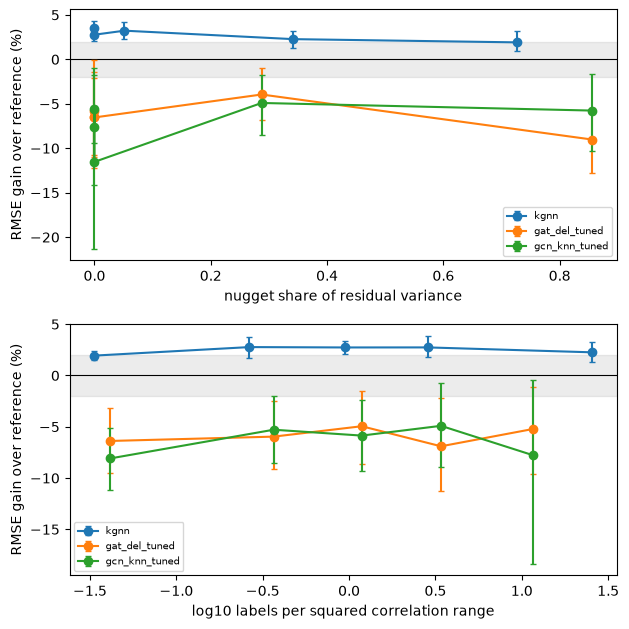

kgnn             noise_frac sign changes at x = none
kgnn             log_lpr    sign changes at x = none
gat_del_tuned    noise_frac sign changes at x = none
gat_del_tuned    log_lpr    sign changes at x = none
gcn_knn_tuned    noise_frac sign changes at x = none
gcn_knn_tuned    log_lpr    sign changes at x = none


In [8]:
if len(df):
    heads = [m for m in ("kgnn", "gat_del_tuned", "gcn_knn_tuned", "gp_ml") if m in set(gains.A)]
    fig = x5.plot_regime(gains, heads, xs=("noise_frac", "log_lpr"), fname=f"{ROOT}/figures/fig_regime_map.png"); plt.show()
    for m in heads:
        for x in ("noise_frac", "log_lpr"):
            bt = x5.binned_gain(gains[gains.A == m], x); print(f"{m:16s} {x:10s} sign changes at x =", [round(c, 2) for c in x5.crossovers(bt)] or "none")

## Part B. Plumbing and leak checks for every new method

Builds a small wall-simulator pool and (1) runs every new predictor once, (2) **corrupts the test labels by 50 dB and requires bit-identical predictions** (same rule as rounds 1-4). Do not trust any later number if this prints a `False`.

In [9]:
if x5.HAVE_TORCH:
    WALL_B = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_wall_b", densities=(20, 50), n_test=100, n_rep=1, min_unit_points=200, outage_q=(0.1, 0.25),
                  outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=3, test_salt="b5")
    names_b = r2.build_wall_units(WALL_B, n_layouts=2, n_tx=2, seed=3, n_pts=350)
    jobs_b = rx.base_jobs() + [dict(name="rk_side", method="rk_side", hp=dict(fset="geo_side"))] + x5.extra_jobs(side=True) + x5.diag_jobs()
    jobs_b = [dict(j, hp={**j.get("hp", {}), **({"steps": 20} if "steps" in j.get("hp", {}) and j["name"] != "rk_gcn_s0" and j["name"] != "gcn_krig_s0" else {})}) for j in jobs_b]
    print("leak check (True = predictions identical when test labels are corrupted):")
    print(x5.leak_check(jobs_b, names_b[0], WALL_B, density=20))
    t = x5.make_tasks5(names_b, WALL_B["densities"], [0], jobs_b, WALL_B, "chk")
    x5.run_tasks5(t, f"{ROOT}/check_B.jsonl", n_jobs=1)
    dB = rc.read_results(f"{ROOT}/check_B.jsonl"); display(dB.groupby("name").agg(ok=("status", lambda s: (s == "ok").mean()), rmse=("rmse", "mean"), sec=("seconds", "mean")).round(3))
    assert (dB.status == "ok").all(), dB[dB.status != "ok"].err.iloc[0]
else:
    print("torch not available: Part B..E need it. Part A/analysis cells run without.")

leak check (True = predictions identical when test labels are corrupted):
{'trend': True, 'idw': True, 'krig_global': True, 'kgnn': True, 'rk_side': True, 'gp_ml': True, 'rbf_spline': True, 'coord_mlp': True, 'rk_gcn': True, 'rk_gcn_s0': True, 'gcn_krig': True, 'gcn_krig_s0': True}
[run_tasks5] 8 tasks, 0 done, 8 to run (n_jobs=1) -> results_ext5_smoke/check_B.jsonl
  8/8 3s failed jobs: 0


,ok,rmse,sec
name,,,
coord_mlp,1.0,6.280,0.013
gcn_krig,1.0,5.441,0.055
gcn_krig_s0,1.0,5.442,0.003
gp_ml,1.0,5.671,0.080
idw,1.0,5.445,0.001
kgnn,1.0,5.124,0.194
krig_global,1.0,5.576,0.011
rbf_spline,1.0,5.305,0.004
rk_gcn,1.0,4.142,0.066


## Part C. Is the GNN a strawman?

**C1 (side information).** In round 1 `gat_del_side` was 36-38% worse than `rk_side` although it receives the *same covariates*. A model that can express `ridge + IDW` should not lose by that much. `rk_gcn` is a label-aware GCN whose zero-initialised head adds a correction to exactly that base (ridge on the same standardised covariates + LOO-IDW of the leftover); `rk_gcn_s0` is the base itself. If `rk_gcn` ~ `rk_s0` ~ `rk_side` the earlier gap was *the GNN failing to rediscover a linear model from 5-20 labels*, which is a statement about sample efficiency, not capacity.

**C2 (selection noise).** `gcn_krig` begins exactly at IDW and keeps a checkpoint only if it lowers validation loss on held-out *labels*. With fewer than 30 labels the validation set has 3-6 points. `gcn_krig` vs `gcn_krig_s0` isolates the cost of that selection.

**C3 (tuning).** One headline arm gets a 3x larger cross-fitted random-search budget; if it still loses, "under-tuned" is not the explanation.

In [10]:
S = dict(n_layouts=4, n_tx=2, n_pts=350, dens=(10, 20), n_test=100, reps=[0, 1], steps=30, trials=3) if SMOKE else \
    dict(n_layouts=16, n_tx=6, n_pts=500, dens=(10, 20, 50, 100), n_test=200, reps=list(range(400, 405)), steps=150, trials=24)
WALL_C = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_wall_c", densities=S["dens"], n_test=S["n_test"], n_rep=len(S["reps"]), min_unit_points=min(300, S["n_pts"] - 100),
              outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=7, test_salt="c5")
names_c = r2.build_wall_units(WALL_C, S["n_layouts"], S["n_tx"], seed=7, n_pts=S["n_pts"]) if x5.HAVE_TORCH else []
jobs_c = (rx.base_jobs() + r2.side_jobs() + x5.extra_jobs(side=True) + x5.diag_jobs() + rx.graph_jobs(("gcn_knn", "gat_del"))) if x5.HAVE_TORCH else []
if SMOKE and x5.HAVE_TORCH: jobs_c = [dict(j, hp={**j.get("hp", {}), **({"steps": S["steps"]} if j.get("hp", {}).get("steps", 0) > 0 else {})}) for j in jobs_c]
if x5.HAVE_TORCH:
    path_c = f"{ROOT}/C_wall.jsonl"
    x5.run_tasks5(x5.make_tasks5(names_c, WALL_C["densities"], S["reps"], jobs_c, WALL_C, "C"), path_c, N_JOBS)
    dC = rc.read_results(path_c); dC["split"] = "random"; dC["family"] = "wall_c"

[run_tasks5] 32 tasks, 0 done, 32 to run (n_jobs=15) -> results_ext5_smoke/C_wall.jsonl
  25/32 13s failed jobs: 0
  32/32 14s failed jobs: 0


In [11]:
if x5.HAVE_TORCH:
    print("C1: side-information GNN vs the SAME-information classical model")
    c1 = x5.contrast_table(dC, SIDE_CONTRASTS, by=("family", "density")); display(c1[["density", "A", "B", "n_clusters", "mean_gain_pct", "ci_lo", "ci_hi", "mean_gain_db", "p_holm", "verdict"]].round(3))
    print("\nC2: cost of validation-based checkpoint selection (positive = training made the model WORSE than its IDW start)")
    c2 = x5.selection_harm(dC); display(c2.round(3))
    print("same, for rk_gcn vs its ridge+IDW start:"); display(x5.selection_harm(dC, "rk_gcn", "rk_gcn_s0").round(3))
    c1.to_csv(f"{ROOT}/C1_side_contrasts.csv", index=False); c2.to_csv(f"{ROOT}/C2_selection_harm.csv", index=False)

C1: side-information GNN vs the SAME-information classical model


,density,A,B,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,p_holm,verdict
0,10,gat_del_side,rk_side,4,-10.765,-29.993,8.562,-0.338,1.0,inconclusive
1,20,gat_del_side,rk_side,4,-25.266,-43.959,-10.518,-1.136,1.0,A worse
2,10,gcn_knn_side,rk_side,4,-19.862,-57.079,6.096,-0.879,1.0,inconclusive
3,20,gcn_knn_side,rk_side,4,-29.834,-51.413,-13.792,-1.342,1.0,A worse
4,10,rk_gcn,rk_side,4,-2.423,-6.131,1.285,-0.027,1.0,inconclusive
5,20,rk_gcn,rk_side,4,-4.754,-7.975,-2.686,-0.258,1.0,A worse
6,10,rk_gcn_s0,rk_side,4,11.097,3.971,18.909,0.935,1.0,A better
7,20,rk_gcn_s0,rk_side,4,1.050,-1.070,3.170,0.051,1.0,inconclusive
8,10,rk_gcn,rk_gcn_s0,4,-16.710,-26.018,-7.402,-0.963,1.0,A worse
9,20,rk_gcn,rk_gcn_s0,4,-5.987,-8.157,-3.817,-0.309,1.0,A worse



C2: cost of validation-based checkpoint selection (positive = training made the model WORSE than its IDW start)


,density,n_fits,mean_harm_pct,ci_lo,ci_hi,share_worse,share_worse_gt_margin,share_better_gt_margin
0,10,16,1.171,-5.556,7.729,0.438,0.438,0.438
1,20,16,2.461,-0.159,5.081,0.500,0.250,0.312


same, for rk_gcn vs its ridge+IDW start:


,density,n_fits,mean_harm_pct,ci_lo,ci_hi,share_worse,share_worse_gt_margin,share_better_gt_margin
0,10,16,16.957,7.720,26.193,0.750,0.75,0.125
1,20,16,5.984,3.611,8.357,0.625,0.50,0.000


In [12]:
# C3: larger cross-fitted tuning budget on the headline side-information GNN (compare to the default-hyper-parameter arm)
if x5.HAVE_TORCH:
    bases = ["gat_del_side", "gcn_knn_side"]; folds = r2.parent_folds(names_c, WALL_C["cache_dir"], 2, "layout")
    best = r2.tune_crossfit(names_c, WALL_C, f"{ROOT}/tuneC", "C3", bases, N_JOBS, 2, "layout", n_trials=S["trials"], tune_rep=2, max_tune_units=40, salt="tuneC5")
    tasks = []
    for f, units in folds.items():
        tasks += x5.make_tasks5(units, WALL_C["densities"], S["reps"], [dict(name="rk_side", method="rk_side", hp=dict(fset="geo_side"))] + r2.tuned_jobs(best[f]), WALL_C, f"C3|f{f}")
    x5.run_tasks5(tasks, f"{ROOT}/C3_tuned.jsonl", N_JOBS)
    d3 = rc.read_results(f"{ROOT}/C3_tuned.jsonl"); d3["split"] = "random"; d3["family"] = "wall_c"
    tn = sorted(n for n in d3.name.unique() if n.endswith("_tuned"))
    c3 = x5.contrast_table(d3, [(n, "rk_side") for n in tn], by=("family", "density")); display(c3[["density", "A", "B", "n_clusters", "mean_gain_pct", "ci_lo", "ci_hi", "mean_gain_db", "verdict"]].round(3))

[run_tasks2] 16 tasks, 0 done, 16 to run (n_jobs=15) -> results_ext5_smoke/tuneC/tune_C3_f0.jsonl
  16/16 15s failed jobs: 0
[run_tasks2] 16 tasks, 0 done, 16 to run (n_jobs=15) -> results_ext5_smoke/tuneC/tune_C3_f1.jsonl
  16/16 15s failed jobs: 0
[run_tasks5] 32 tasks, 0 done, 32 to run (n_jobs=15) -> results_ext5_smoke/C3_tuned.jsonl
  25/32 9s failed jobs: 0
  32/32 10s failed jobs: 0


,density,A,B,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,verdict
0,10,gat_del_side_tuned,rk_side,4,-17.644,-52.548,7.794,-0.651,inconclusive
1,20,gat_del_side_tuned,rk_side,4,-30.964,-53.511,-10.678,-1.390,A worse
2,10,gcn_knn_side_tuned,rk_side,4,-19.778,-50.231,3.298,-0.902,inconclusive
3,20,gcn_knn_side_tuned,rk_side,4,-36.257,-67.922,-15.816,-1.616,A worse


## Part D. The training-scale axis (where GNNs are *supposed* to win)

Everything in rounds 1-4 trains a GNN on one map or on <= 40 source units. Here the knobs that the positive GNN literature relies on are made explicit:

* **K = number of source layouts used for pre-training** (4, 16, 64; each with 4 transmitters), GNNs (`gcn_knn`, `gat_del`, and the side-information versions) and an attentive neural process, all pre-trained **only on source layouts, evaluated only on 16 disjoint held-out layouts**.
* **Labels per held-out map: 100 ... 2000** (the spectrum-cartography regime, not the Wi-Fi-fingerprint regime).
* Zero-shot (`xfer*`) and 30-step fine-tuned (`xferft*`) variants, compared with every classical comparator in the frozen plan: `idw`, `rk_side`, `krig_global`, `gp_ml`, `kgnn`.

**Reading the result.** Either a learned model's CI clears the margin over *all* comparators somewhere (then you have a real "when GNNs help", and its location is the paper's headline) or it never does (then the negative result is far stronger than rounds 1-4, because the regime reviewers care about was covered).

In [13]:
SD = dict(n_eval=4, n_train=8, n_tx=2, n_pts=500, dens=(50, 100), src_dens=(50,), n_test=100, Ks=(2, 8), gnn_steps=40, np_steps=200, ft=10, reps=[0]) if SMOKE else \
     dict(n_eval=16, n_train=64, n_tx=4, n_pts=3000, dens=(100, 300, 1000, 2000), src_dens=(100, 300, 1000), n_test=300, Ks=(4, 16, 64), gnn_steps=1500, np_steps=6000, ft=30, reps=list(range(500, 503)))
WALL_D = dict(rc.DEFAULT_CFG, cache_dir=f"{ROOT}/cache_scale", densities=SD["dens"], n_test=SD["n_test"], n_rep=len(SD["reps"]), min_unit_points=min(300, SD["n_pts"] - 100),
              outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", seed=5, test_salt="scale5")
WALL_D_SRC = {**WALL_D, "densities": SD["src_dens"]}
PRE_D = {**r2.PRE_GEO, **r2.PRE_SIDE} if x5.HAVE_TORCH else {}
if x5.HAVE_TORCH:
    eval_names, train_layouts = x5.build_scale_pool(WALL_D, SD["n_eval"], SD["n_train"], SD["n_tx"], SD["n_pts"], seed=11)
    print(len(eval_names), "evaluation units in", SD["n_eval"], "layouts |", len(train_layouts), "source layouts available")
    assert not set(eval_names) & {n for L in train_layouts for n in L}

8 evaluation units in 4 layouts | 8 source layouts available


In [14]:
if x5.HAVE_TORCH:
    gnn_paths, np_paths = x5.pretrain_scale(train_layouts, SD["Ks"], WALL_D_SRC, PRE_D, f"{ROOT}/pretrained_scale", SD["gnn_steps"], SD["np_steps"])
    print(len(gnn_paths), "GNN priors,", len(np_paths), "neural-process priors")

=== K=2 source layouts, 4 source units
  pretraining K2 / cross / gat_del on 4 source units
  pretraining K2 / cross / gcn_knn on 4 source units
  pretraining K2 / cross / gat_del_side on 4 source units
  pretraining K2 / cross / gcn_knn_side on 4 source units
    NP step 200/200 train 0.579 val 0.566
=== K=8 source layouts, 16 source units
  pretraining K8 / cross / gat_del on 16 source units
  pretraining K8 / cross / gcn_knn on 16 source units
  pretraining K8 / cross / gat_del_side on 16 source units
  pretraining K8 / cross / gcn_knn_side on 16 source units
    NP step 200/200 train 0.560 val 0.476
8 GNN priors, 2 neural-process priors


In [15]:
if x5.HAVE_TORCH:
    jobs_d = x5.scale_jobs(SD["Ks"], gnn_paths, np_paths, PRE_D, SD["ft"], side=True)
    if SMOKE: jobs_d = [dict(j, hp={**j.get("hp", {}), **({"steps": 20} if j.get("hp", {}).get("steps", 0) > 20 else {})}) for j in jobs_d]
    print(len(jobs_d), "jobs per task:", [j["name"] for j in jobs_d])
    path_d = f"{ROOT}/D_scale.jsonl"
    x5.run_tasks5(x5.make_tasks5(eval_names, WALL_D["densities"], SD["reps"], jobs_d, WALL_D, "D"), path_d, N_JOBS)
    dD = rc.read_results(path_d); print(len(dD), "rows,", (dD.status == "ok").mean(), "ok")

32 jobs per task: ['trend', 'idw', 'krig_global', 'kgnn', 'gp_ml', 'rbf_spline', 'coord_mlp', 'rk_gcn', 'rk_gcn_s0', 'gcn_knn', 'gat_del', 'gcn_knn_side', 'gat_del_side', 'rk_side', 'xfer2_gat_del', 'xferft2_gat_del', 'xfer2_gcn_knn', 'xferft2_gcn_knn', 'xfer2_gat_del_side', 'xferft2_gat_del_side', 'xfer2_gcn_knn_side', 'xferft2_gcn_knn_side', 'np_prior2', 'xfer8_gat_del', 'xferft8_gat_del', 'xfer8_gcn_knn', 'xferft8_gcn_knn', 'xfer8_gat_del_side', 'xferft8_gat_del_side', 'xfer8_gcn_knn_side', 'xferft8_gcn_knn_side', 'np_prior8']
[run_tasks5] 16 tasks, 0 done, 16 to run (n_jobs=15) -> results_ext5_smoke/D_scale.jsonl
  16/16 9s failed jobs: 0
512 rows, 1.0 ok


,density,method,ref,K,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,verdict
16,50,np_prior2,idw,2,4,-27.450,-31.440,-22.569,-1.423,A worse
18,50,np_prior8,idw,8,4,-22.706,-29.204,-16.207,-1.200,A worse
26,50,xfer2_gat_del,idw,2,4,-41.084,-75.719,-13.906,-2.305,A worse
34,50,xfer8_gat_del,idw,8,4,-41.084,-75.719,-13.906,-2.305,A worse
28,50,xfer2_gat_del_side,rk_side,2,4,-94.348,-187.640,-35.370,-3.516,A worse
36,50,xfer8_gat_del_side,rk_side,8,4,-94.348,-187.640,-35.370,-3.516,A worse
30,50,xfer2_gcn_knn,idw,2,4,-41.084,-75.719,-13.906,-2.305,A worse
38,50,xfer8_gcn_knn,idw,8,4,-41.084,-75.719,-13.906,-2.305,A worse
32,50,xfer2_gcn_knn_side,rk_side,2,4,-94.348,-187.640,-35.370,-3.516,A worse
40,50,xfer8_gcn_knn_side,rk_side,8,4,-94.348,-187.640,-35.370,-3.516,A worse


classical / from-scratch reference gains (K = 0):


,density,method,ref,mean_gain_pct,ci_lo,ci_hi,verdict
0,50,coord_mlp,idw,-21.679,-38.579,-6.962,A worse
2,50,gat_del,idw,-8.848,-13.446,-3.926,A worse
4,50,gat_del_side,rk_side,-29.059,-43.034,-15.856,A worse
6,50,gcn_knn,idw,-11.077,-16.705,-5.784,A worse
8,50,gcn_knn_side,rk_side,-35.815,-57.388,-14.243,A worse
10,50,gp_ml,idw,0.269,-2.530,2.817,inconclusive
12,50,kgnn,idw,1.312,-1.011,4.056,inconclusive
14,50,krig_global,idw,0.222,-0.448,0.892,equivalent (CI within +/-2%)
20,50,rbf_spline,idw,-3.810,-8.786,0.804,inconclusive
22,50,rk_gcn,rk_side,0.601,-2.523,3.998,inconclusive


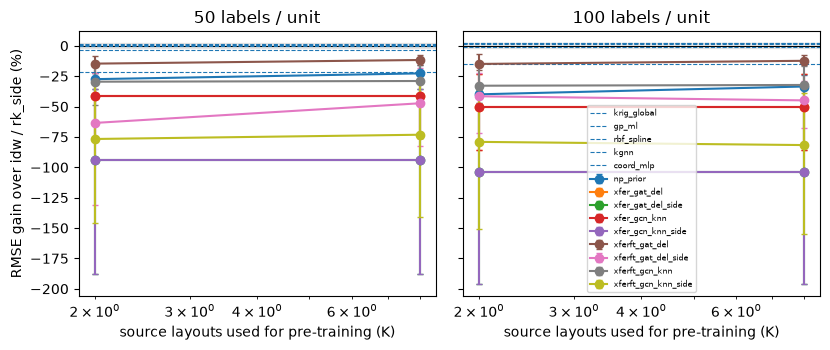

In [16]:
if x5.HAVE_TORCH:
    tabD = x5.scale_table(dD); tabD.to_csv(f"{ROOT}/D_scale_table.csv", index=False)
    display(tabD[tabD.K > 0].sort_values(["density", "kind", "tag", "K"])[["density", "method", "ref", "K", "n_clusters", "mean_gain_pct", "ci_lo", "ci_hi", "mean_gain_db", "verdict"]].round(3))
    print("classical / from-scratch reference gains (K = 0):"); display(tabD[tabD.K == 0].sort_values(["density", "method"])[["density", "method", "ref", "mean_gain_pct", "ci_lo", "ci_hi", "verdict"]].round(3))
    x5.plot_scale(tabD, f"{ROOT}/figures/fig_scale_axis.png"); plt.show()

In [17]:
# Claim rule from the frozen plan: a learned model must beat EVERY classical comparator, CI lower bound above the margin, at some (K, density).
if x5.HAVE_TORCH:
    learned = [n for n in dD.name.unique() if x5._SCALE_RE.match(n) or n in ("gcn_knn", "gat_del", "gcn_knn_side", "gat_del_side", "rk_gcn", "coord_mlp")]
    comps = [c for c in ("idw", "rk_side", "krig_global", "gp_ml", "kgnn") if c in set(dD.name)]
    lst = [(a, b) for a in learned for b in comps if a != b]
    cD = x5.contrast_table(dD.assign(family="wall_d", split="random"), lst, by=("family", "density")); cD.to_csv(f"{ROOT}/D_vs_all_comparators.csv", index=False)
    # one row per (learned model, density): worst-case lower CI bound across comparators
    worst = cD.groupby(["A", "density"]).agg(worst_ci_lo=("ci_lo", "min"), worst_gain_pct=("mean_gain_pct", "min"), n_comp=("B", "nunique")).reset_index()
    worst["clears_margin_vs_all"] = worst.worst_ci_lo > x5.MARGIN_PCT
    display(worst.sort_values("worst_ci_lo", ascending=False).head(15).round(3))
    print("\nLEARNED MODELS THAT BEAT EVERY COMPARATOR BY > margin:", worst[worst.clears_margin_vs_all][["A", "density"]].values.tolist() or "NONE")

,A,density,worst_ci_lo,worst_gain_pct,n_comp,clears_margin_vs_all
15,rk_gcn,100,-1.842,0.262,5,False
14,rk_gcn,50,-2.523,0.601,5,False
4,gat_del_side,50,-43.034,-29.059,5,False
8,gcn_knn_side,50,-57.388,-35.815,5,False
5,gat_del_side,100,-58.925,-33.695,5,False
9,gcn_knn_side,100,-61.872,-39.464,5,False
7,gcn_knn,100,-67.618,-41.189,5,False
43,xferft8_gat_del_side,100,-67.984,-44.910,5,False
40,xferft8_gat_del,50,-69.818,-48.240,5,False
35,xferft2_gat_del_side,100,-71.445,-41.531,5,False



LEARNED MODELS THAT BEAT EVERY COMPARATOR BY > margin: NONE


## Part E. Missing baselines on your existing real Wi-Fi units

Adds `gp_ml` (Matern-1.5, ARD length scales + nugget by maximum marginal likelihood), `rbf_spline` (thin-plate smoothing spline, smoothing by inner 5-fold CV) and `coord_mlp` (Fourier-feature network, per-unit) next to `idw`, `krig_global`, `kgnn` on the **same units, densities and splits** as round 3 (fresh test salt and replicate ids). `rk_side`/side models are not included (UJI/SOD have no side information).

Set `E_FAMILIES` to point at your caches; names are taken from your earlier results so the units are identical.

In [18]:
E_CFG = {"uji": dict(dens=(5, 10, 20), n_test=20), "sod": dict(dens=(5, 10, 20, 60), n_test=40)}
def find_cache(name):
    for cd in CACHE_DIRS:
        if os.path.exists(os.path.join(cd, "units", name.replace("|", "__") + ".npz")): return cd
if x5.HAVE_TORCH:
    E_FAMILIES = {}
    if len(df):
        for fam, spec in E_CFG.items():
            nm = sorted(df[df.family == fam].unit.unique()) if "family" in df else []
            nm = [n for n in nm if find_cache(n)]
            if nm: E_FAMILIES[fam] = dict(names=nm, cache=find_cache(nm[0]))
    if SMOKE and not E_FAMILIES:                     # fake-data pass so the whole chain can be exercised
        E_FAMILIES = {"wall": dict(names=names_c, cache=WALL_C["cache_dir"])}; E_CFG["wall"] = dict(dens=(20, 50), n_test=100)
    print({k: len(v["names"]) for k, v in E_FAMILIES.items()})

{'uji': 251, 'sod': 97}


In [19]:
if x5.HAVE_TORCH and E_FAMILIES:
    for fam, spec in E_FAMILIES.items():
        for split in ("random", "blocked"):
            cfg_e = dict(rx.UJI_CFG, cache_dir=spec["cache"], densities=E_CFG[fam]["dens"], n_test=E_CFG[fam]["n_test"], n_rep=3, trend_policy="robust", test_salt="e5",
                         split_mode=split, block_buffer=0.0, outage_q=(0.1, 0.25), outage_abs_dbm=(), outage_min_class=8, min_unit_points=1)
            if fam == "wall": cfg_e = {**WALL_C, "split_mode": split, "test_salt": "e5"}
            jobs_e = rx.base_jobs() + x5.extra_jobs(side=False)
            if SMOKE: jobs_e = [dict(j, hp={**j.get("hp", {}), **({"steps": 20} if j.get("hp", {}).get("steps", 0) > 20 else {})}) for j in jobs_e]
            out = f"{ROOT}/smoke/{fam}/{fam}_{split}.jsonl" if SMOKE else f"{ROOT}/E/{fam}/{fam}_{split}.jsonl"
            x5.run_tasks5(x5.make_tasks5(spec["names"], cfg_e["densities"], [600, 601, 602], jobs_e, cfg_e, f"E|{fam}|{split}"), out, N_JOBS)
    dE = x5.load_results([f"{ROOT}/smoke/*/*.jsonl" if SMOKE else f"{ROOT}/E/*/*.jsonl"])
    E_CON = [(m, "idw") for m in ("krig_global", "kgnn", "gp_ml", "rbf_spline", "coord_mlp")] + [("gp_ml", "krig_global"), ("kgnn", "gp_ml")]
    cE = x5.contrast_table(dE, E_CON, by=("family", "split", "density")); cE.to_csv(f"{ROOT}/E_baselines.csv", index=False)
    display(cE[["family", "split", "density", "A", "B", "n_clusters", "mean_gain_pct", "ci_lo", "ci_hi", "mean_gain_db", "p_holm", "verdict"]].round(3))

[run_tasks5] 2259 tasks, 0 done, 2259 to run (n_jobs=15) -> results_ext5_smoke/smoke/uji/uji_random.jsonl
  first failure: trend uji|b0f0|WAP024
Traceback (most recent call last):
  File "/home/praaneshnair/gitProjects/prism/rmbench_ext5.py", line 401, in run_task5
    u0 = rx.get_unit_ext(task["unit"], cfg["cache_dir"])
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/praaneshnair/gitProjects/prism/rmbench_ext.py", line 140, in get_unit_ext
    u = dict(rc.get_unit(name, cache_dir))
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/praaneshnair/gitProjects/prism/rmbench_core.py", line 250, in get_unit
    return load_unit_file(os.path.join(cache_dir, "units", name.replace("|", "__") + ".npz"))
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: 'results_ext2/cache_uji/units/uji__b0f0__WAP024.npz'

  25/2259 6s failed jobs: 147
  50/2259 6s failed jobs: 315
  75

,family,split,density,A,B,n_clusters,mean_gain_pct,ci_lo,ci_hi,mean_gain_db,p_holm,verdict
0,sod,blocked,5,krig_global,idw,5,-4.931,-7.236,-2.331,-0.470,1.000,A worse
1,sod,blocked,10,krig_global,idw,5,-0.322,-1.209,0.962,-0.085,1.000,equivalent (CI within +/-2%)
2,sod,blocked,20,krig_global,idw,5,-1.162,-4.063,0.616,-0.115,1.000,inconclusive
3,sod,blocked,60,krig_global,idw,5,-0.490,-2.487,1.219,-0.070,1.000,inconclusive
4,sod,random,5,krig_global,idw,5,-8.434,-11.042,-6.602,-0.720,1.000,A worse
...,...,...,...,...,...,...,...,...,...,...,...,...
93,uji,blocked,10,kgnn,gp_ml,12,3.578,1.816,5.038,0.438,0.210,A better
94,uji,blocked,20,kgnn,gp_ml,12,2.521,0.793,4.457,0.304,0.090,A better
95,uji,random,5,kgnn,gp_ml,12,7.544,5.087,9.827,0.785,0.090,A better
96,uji,random,10,kgnn,gp_ml,12,5.771,4.686,6.814,0.496,0.048,A better


In [20]:
# Re-run Part A's regime map including the new baselines (re-execute the Part A cells after this one).
if SMOKE and x5.HAVE_TORCH and 'dE' in globals():
    print("SMOKE: results written to", f"{ROOT}/smoke/", "- re-run Part A now; it picks them up.")

SMOKE: results written to results_ext5_smoke/smoke/ - re-run Part A now; it picks them up.


## Part F. More data (templates)

Step 5 of the plan: >= 12 independent environments so building-level inference has power. Two adapters that already exist in your code do most of the work.

**F1. Any Wi-Fi/BLE fingerprint CSV** (one row per reference point, one column per AP, `100` = not detected): `rmbench_ext2.build_wifi_units`. Candidates: Tampere, UTSIndoorLoc, MSLoc, Lib-/Office datasets. Check the licence and the column schema first; this cell only runs if you provide a path.

In [21]:
NEW_WIFI = dict(                        # fill in, e.g. name -> dict(csv=..., bcol=..., fcol=..., xcol=..., ycol=..., wprefix=...)
    # "tampere": dict(csv="data/tampere/train.csv", bcol="BUILDINGID", fcol="FLOOR", xcol="X", ycol="Y", wprefix="AP"),
)
if x5.HAVE_TORCH and NEW_WIFI:
    for ds, a in NEW_WIFI.items():
        raw = pd.read_csv(a["csv"]); cfg_n = dict(rx.UJI_CFG, cache_dir=f"{ROOT}/cache_{ds}", densities=(5, 10, 20), n_test=20, min_unit_points=41, trend_policy="robust")
        tab = r2.wifi_floor_table(raw, a["bcol"], a["fcol"], a["xcol"], a["ycol"], a["wprefix"]); display(tab.head())
        units, dropped = r2.build_wifi_units(raw, cfg_n, ds, a["bcol"], a["fcol"], a["xcol"], a["ycol"], a["wprefix"])
        print(ds, len(units), "units;", len(set(rx.get_unit_ext(n, cfg_n["cache_dir"])["layout"] for n in units)), "layouts")
        # then evaluate exactly like Part E with jobs rx.base_jobs() + x5.extra_jobs() and the same contrasts
else:
    print("NEW_WIFI is empty: nothing to build.")

NEW_WIFI is empty: nothing to build.


**F2. DeepMIMO with a target that is not trivially smooth** (replaces the 100%-LOS `i1_2p5` path-sum): the *narrowband channel power* target (`power_def='channel'` / `DM_HARD_CFG`), more NLOS-heavy scenarios. Needs the DeepMIMO package and network access.

In [22]:
RUN_DM = False
if RUN_DM and x5.HAVE_TORCH:
    cfg_dm = dict(rx.DM_HARD_CFG, cache_dir=f"{ROOT}/cache_dm_nb", outage_abs_dbm=(), outage_min_class=8, trend_policy="robust", test_salt="f5")
    ok_dm, dropped_dm = rx.build_dm_units(["i2_28b", "i3_60"], cfg_dm)          # add NLOS-heavy scenarios you have installed
    for n, why in dropped_dm: print("dropped:", n, why)
    by = rx.layouts_of(ok_dm, cfg_dm["cache_dir"]); print({k: len(v) for k, v in by.items()}, "-> units per layout. Descriptive only unless >= 5 layouts.")

## Part G. Claim table and the wording the data allow

Collects every verdict produced above and maps it to the wording permitted by the frozen claim rule. Nothing in this section is a new test.

In [23]:
parts = {}
for nm, p in (("A_regime", "regime_contrasts.csv"), ("C1_side", "C1_side_contrasts.csv"), ("D_vs_all", "D_vs_all_comparators.csv"), ("E_baselines", "E_baselines.csv")):
    f = f"{ROOT}/{p}"
    if os.path.exists(f): parts[nm] = pd.read_csv(f).assign(part=nm)
claims = pd.concat(parts.values(), ignore_index=True) if parts else pd.DataFrame()
WORDING = {"A better": "A improves on B (give % and dB; check it exceeds the margin before calling it practically relevant)",
           "A worse": "A is worse than B in this cell",
           "inconclusive": "the advantage was not established; per-cell numbers may be shown but not called confirmed",
           "too few clusters": "not enough independent clusters for inference; descriptive only"}
if len(claims):
    claims["allowed_wording"] = claims.verdict.map(lambda v: "A and B are equivalent within +/-%g%%" % MARGIN_PCT if str(v).startswith("equivalent") else WORDING.get(v, ""))
    claims.to_csv(f"{ROOT}/final_claims.csv", index=False)
    display(claims.groupby(["part", "verdict"]).size().unstack(fill_value=0))
    print("\nFull table:", f"{ROOT}/final_claims.csv")

verdict,A better,A worse,equivalent (CI within +/-2%),inconclusive,too few clusters
part,,,,,
A_regime,24,57,9,36,108
C1_side,1,5,0,4,0
D_vs_all,8,221,1,10,0
E_baselines,24,36,6,32,0



Full table: results_ext5_smoke/final_claims.csv


In [24]:
# Figures for the paper: regime map (Part A) and scale axis (Part D) are already saved; list what exists.
for f in sorted(glob.glob(f"{ROOT}/figures/*.png")): print(f)

results_ext5_smoke/figures/fig_regime_map.png
results_ext5_smoke/figures/fig_scale_axis.png


### How to read the outcomes (decide the paper's headline from these, mechanically)

| Outcome | Headline you may write |
|---|---|
| Part D finds a learned model clearing the margin over every comparator at some (K, density) | **"GNNs help when X"**, X = the (K, labels, covariate) region; Part A gives the covariate side of the same story. Report it with the dB gain, not only %. |
| Part D finds none, C1 shows `rk_gcn ~ rk_side`, C2 shows selection cost > 0 at low labels | **"No tested regime shows a practically significant GNN gain; failures at low labels are sample-efficiency and checkpoint-selection effects, not capacity."** |
| C1 shows `rk_gcn` also loses to `rk_side` by a clear margin | Debug before writing anything: the base or the training loop is wrong. |
| Part A's `lofo_r2` <= 0 | Do not present the regime map as predictive; present it as descriptive and say so. |
| Part E: `gp_ml` ~ `kgnn` | Your "KGNN" edge is a Matern-kriging edge; say "local kriging", not "GNN". |